# Exploración del dataset (contextualización)

Tamaños, rango dinámico, histogramas por clase, desbalance, casos con varias máscaras y marcas del ecógrafo.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [ ]:
from busi.datos import listar_casos, cargar_caso

casos = listar_casos()
casos['clase'].value_counts()

#celda que clasifica los casos por clase y los guarda en un archivo CSV

clase
benign       437
malignant    210
normal       133
Name: count, dtype: int64

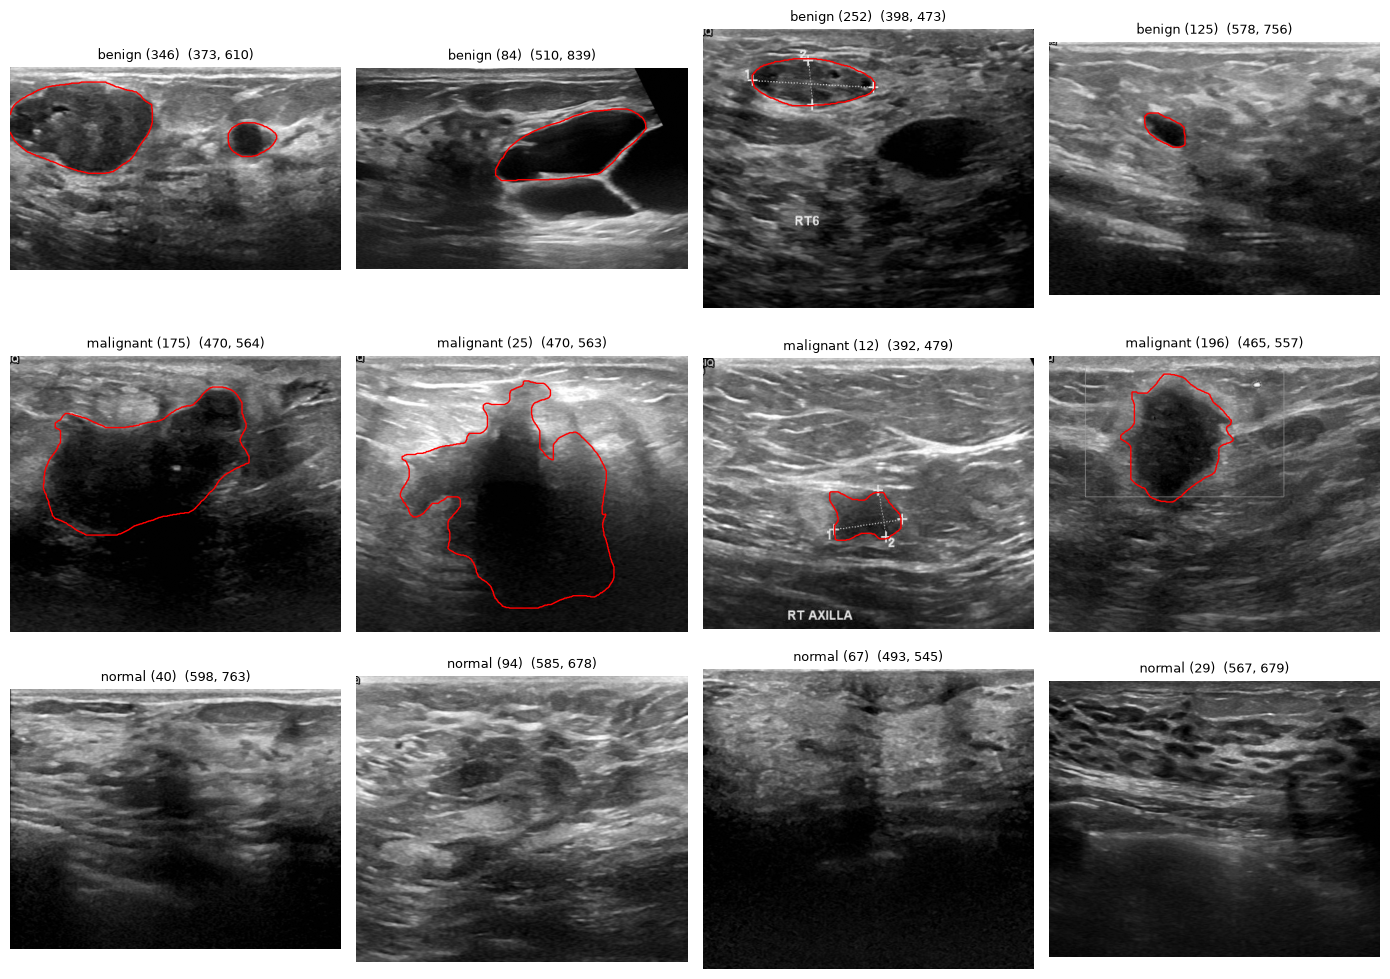

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(14, 10))   # arma una grilla de 12 recuadros: una fila por clase, 4 casos

for fila, clase in zip(axes, ["benign", "malignant", "normal"]):
    # 4 casos al azar de esta clase (random_state fijo = elije una vey los random y luego siempre los mismos para que veamos las 3 la misma grilla)
    ejemplos = casos[casos["clase"] == clase].sample(4, random_state=13)

    for ax, (_, caso) in zip(fila, ejemplos.iterrows()):
        img, mascara = cargar_caso(caso)                 # imagen + máscara del radiólogo
        ax.imshow(img, cmap="gray")
        if mascara.any():                                # las "normal" no tienen lesión
            ax.contour(mascara, levels=[0.5], colors="red", linewidths=1)  # borde en rojo
        ax.set_title(f"{caso['id']}  {img.shape}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Observaciones

1. **Tamaño variable:** las imágenes no tienen un tamaño fijo de 500 × 500 px como indica el artículo del dataset; en esta muestra van de ~370 a ~840 px de ancho. Se cuantifica en la celda siguiente.
2. **Lesiones benignas:** forma ovalada o redondeada, bordes lisos y bien definidos, interior hipoecoico (oscuro) y bastante homogéneo.
3. **Lesiones malignas:** bordes irregulares, con lobulaciones o proyecciones; en algunos casos aparece una **sombra acústica posterior** (zona oscura debajo de la lesión). Coincide con los rasgos de malignidad de BI-RADS.
4. **Marcas del ecógrafo:** se observan *calipers* (cruces de medición), líneas punteadas, textos (ej. "RT AXILLA", "RT6") y recuadros superpuestos a la imagen. No son tejido.
5. **Marcas sobre la lesión:** en varias imágenes los *calipers* caen justo sobre el borde del tumor, por lo que alterarían la textura y la segmentación. Esto justifica la etapa de reconstrucción (Parte 1).